**GitHub Repository:** https://github.com/2026545-git/Statistical-techniques-Sept26

# Statistical Analysis of Bank Marketing Data

**Module:** Statistics for Data Analytics

**Assessment:** CA1

**Dataset:** Bank Marketing Dataset

## 1. Introduction
This notebook presents a statistical analysis of a bank marketing dataset using Python.
The analysis includes data cleaning, descriptive statistics, data visualisation, and three probability distributions: Binomial, Poisson, and Normal.
The aim is to explore customer characteristics, marketing campaign outcomes, and the suitability of different probability distributions for the selected variables.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import binom, norm

df = pd.read_csv("bank-full.csv")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. Data Cleaning

I checked the dataset for missing values, duplicates and unknown values.

There were no missing values or duplicates. Some columns had unknown values, so I kept them in the dataset.

In [2]:
df_clean = df.copy()

In [3]:
print(df_clean.isnull().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [4]:
unknown_counts = (df_clean == "unknown").sum()

print(unknown_counts[unknown_counts > 0])

job            288
education     1857
contact      13020
poutcome     36959
dtype: int64


In [5]:
duplicates = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicates)


Number of duplicate rows: 0


## 3. Descriptive Statistics and Data Visualisation

In this section, I used Python to check the main information in the dataset, such as mean, median, minimum and maximum values.

I also created some graphs to understand the data better and see how the values are distributed.

In [6]:
display(df_clean.describe())

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


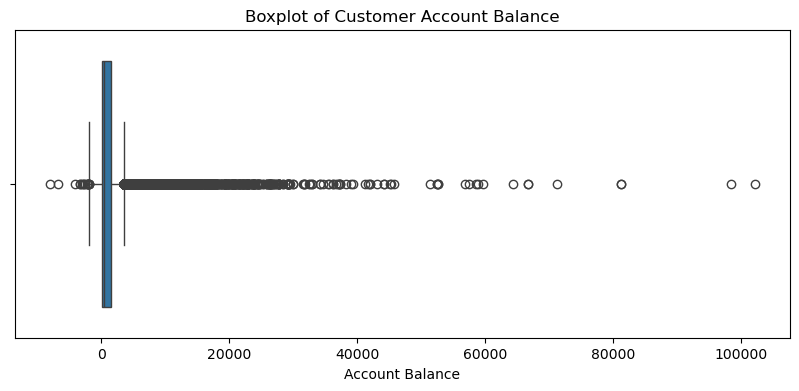

In [7]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df_clean["balance"])

plt.title("Boxplot of Customer Account Balance")
plt.xlabel("Account Balance")
plt.show()

In [8]:
df_clean[["age", "balance", "duration",
          "campaign"]].describe().round(2)

,age,balance,duration,campaign
count,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,258.16,2.76
std,10.62,3044.77,257.53,3.10
min,18.00,-8019.00,0.00,1.00
25%,33.00,72.00,103.00,1.00
50%,39.00,448.00,180.00,2.00
75%,48.00,1428.00,319.00,3.00
max,95.00,102127.00,4918.00,63.00


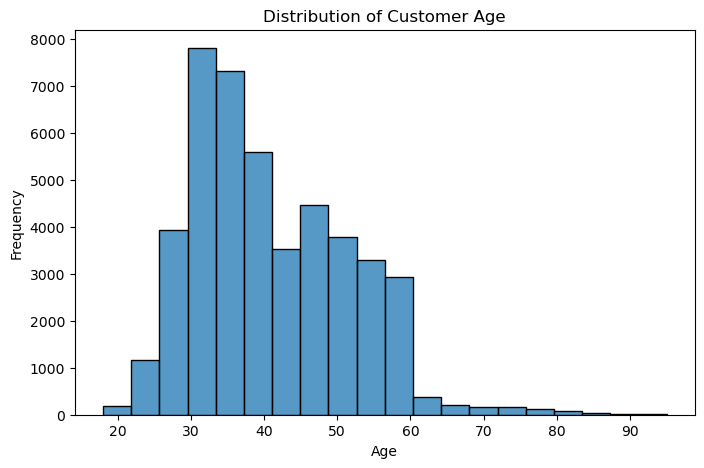

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(df_clean["age"], bins=20)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

y
no     39922
yes     5289
Name: count, dtype: int64


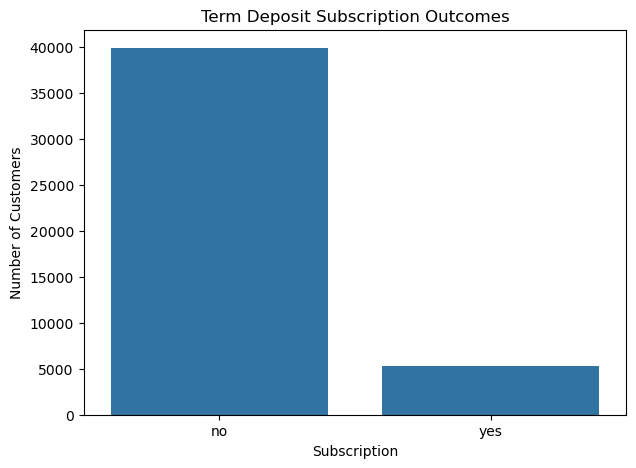

In [10]:
print(df_clean["y"].value_counts())
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="y")

plt.title("Term Deposit Subscription Outcomes")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

## 4. Binomial Distribution

I used the Binomial distribution to calculate the probability of customers subscribing to a term deposit.

The result can be either yes or no, so the Binomial distribution is suitable for this example.

In [11]:
p = (df_clean["y"] == "yes").mean()

print("Probability of subscription:", round(p, 4))

Probability of subscription: 0.117


In [12]:
n = 10
k = 2

probability = binom.pmf(k, n, p)

print("Probability of exactly 2 subscriptions:",
      round(probability, 4))

Probability of exactly 2 subscriptions: 0.2276


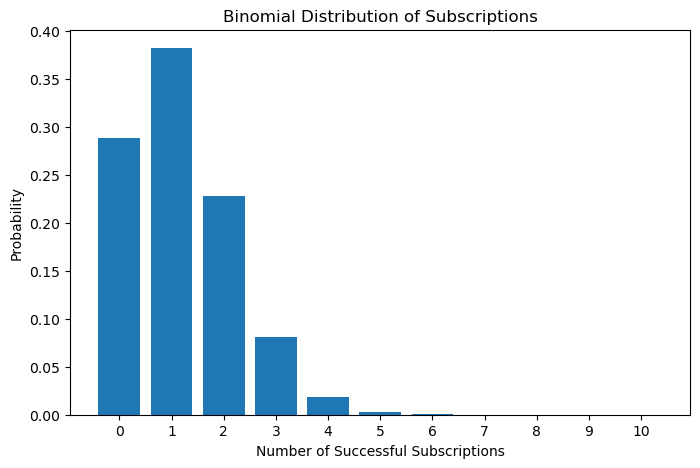

In [13]:
n = 10
x = np.arange(0, n + 1)

pmf_values = binom.pmf(x, n=n, p=p)

plt.figure(figsize=(8, 5))

plt.bar(x, pmf_values)

plt.title("Binomial Distribution of Subscriptions")
plt.xlabel("Number of Successful Subscriptions")
plt.ylabel("Probability")
plt.xticks(x)

plt.show()

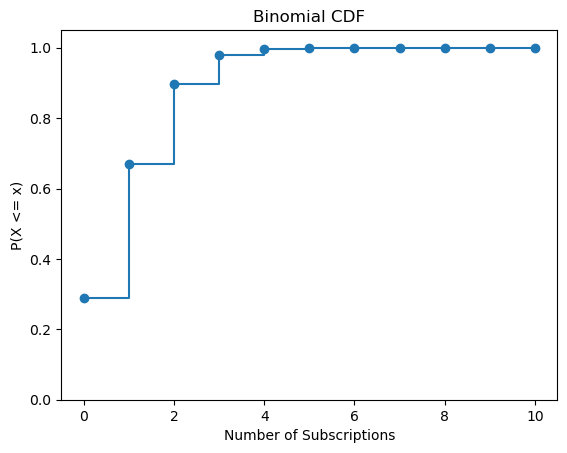

In [14]:
n = 10
x = np.arange(0, n + 1)
cdf_values = binom.cdf(x, n=n, p=p)

plt.step(x, cdf_values, where="post", marker="o")
plt.xlabel("Number of Subscriptions")
plt.ylabel("P(X <= x)")
plt.title("Binomial CDF")
plt.ylim(0, 1.05)
plt.show()

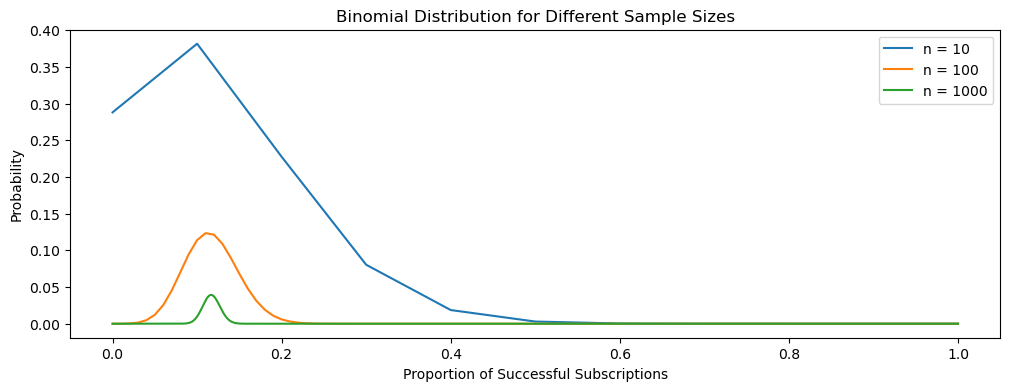

In [15]:
plt.figure(figsize=(12, 4))

for n in [10, 100, 1000]:
    x = np.arange(0, n + 1)
    probabilities = stats.binom.pmf(x, n, p)

    plt.plot(x / n, probabilities, label=f"n = {n}")

plt.title("Binomial Distribution for Different Sample Sizes")
plt.xlabel("Proportion of Successful Subscriptions")
plt.ylabel("Probability")
plt.legend()
plt.show()

## 5. Poisson Distribution

I used the Poisson distribution to calculate the probability of contacting a customer a certain number of times.

I used the average number of contacts from the campaign column for this calculation.

In [16]:
lam = df_clean["campaign"].mean()
variance = df_clean["campaign"].var()

print("Mean (lambda):", round(lam, 2))
print("Variance:", round(variance, 2))

Mean (lambda): 2.76
Variance: 9.6


In [17]:
k = 3

poisson_prob = stats.poisson.pmf(k, lam)

print("Probability of exactly 3 contacts:",
      round(poisson_prob, 4))

Probability of exactly 3 contacts: 0.2219


In [18]:
for n in [100, 1000, 10000]:
    sample = df_clean["campaign"].sample(n=n, random_state=42)

    print("Sample size:", n)
    print("Mean:", round(sample.mean(), 2))
    print("Variance:", round(sample.var(), 2))
    print()

Sample size: 100
Mean: 2.47
Variance: 6.94

Sample size: 1000
Mean: 2.78
Variance: 8.07

Sample size: 10000
Mean: 2.76
Variance: 8.99



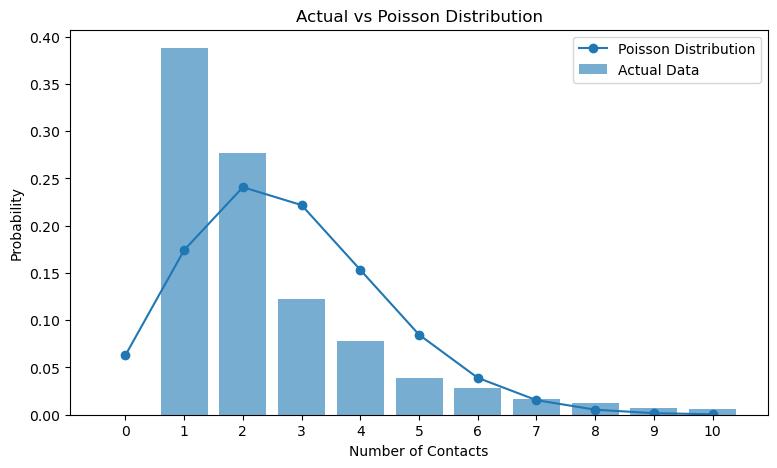

In [19]:
x = np.arange(0, 11)

actual = df_clean["campaign"].value_counts(normalize=True)
poisson = stats.poisson.pmf(x, lam)

plt.figure(figsize=(9, 5))

plt.bar(x, actual.reindex(x, fill_value=0),
        alpha=0.6, label="Actual Data")

plt.plot(x, poisson, marker="o",
         label="Poisson Distribution")

plt.title("Actual vs Poisson Distribution")
plt.xlabel("Number of Contacts")
plt.ylabel("Probability")
plt.xticks(x)
plt.legend()
plt.show()

## 6. Normal Distribution

I used the Normal distribution to analyse the age of customers.

I calculated the mean and standard deviation and used graphs to see how the ages are distributed.

In [20]:
mean_age = df_clean["age"].mean()
std_age = df_clean["age"].std()
print("Mean (mean_age):", round(mean_age, 2))
print("Standard Deviation (std_age):", round(std_age, 2))

Mean (mean_age): 40.94
Standard Deviation (std_age): 10.62


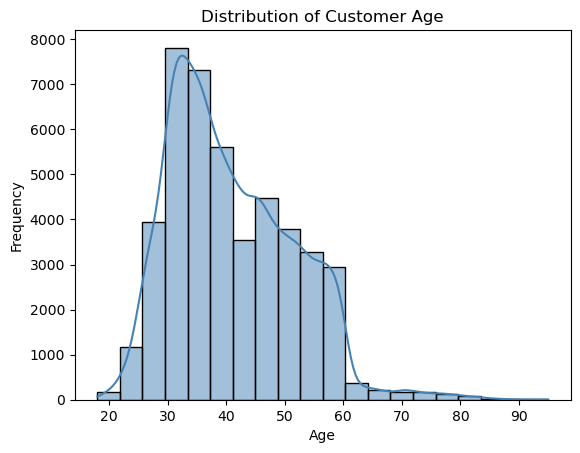

In [21]:
age = df_clean["age"]

sns.histplot(age, kde=True, bins=20, color="steelblue")

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of Customer Age")
plt.show()

In [22]:
within_1std = ((age >= mean_age - std_age) &
               (age <= mean_age + std_age)).mean() * 100

within_2std = ((age >= mean_age - 2*std_age) &
               (age <= mean_age + 2*std_age)).mean() * 100

within_3std = ((age >= mean_age - 3*std_age) &
               (age <= mean_age + 3*std_age)).mean() * 100

print("Within 1 SD:", round(within_1std, 2), "%")
print("Within 2 SD:", round(within_2std, 2), "%")
print("Within 3 SD:", round(within_3std, 2), "%")

Within 1 SD: 66.05 %
Within 2 SD: 97.77 %
Within 3 SD: 99.16 %


In [23]:
# Z-score for a 50-year-old customer

customer_age = 50

z_score = (customer_age - mean_age) / std_age

print("Z-score:", round(z_score, 2))

Z-score: 0.85


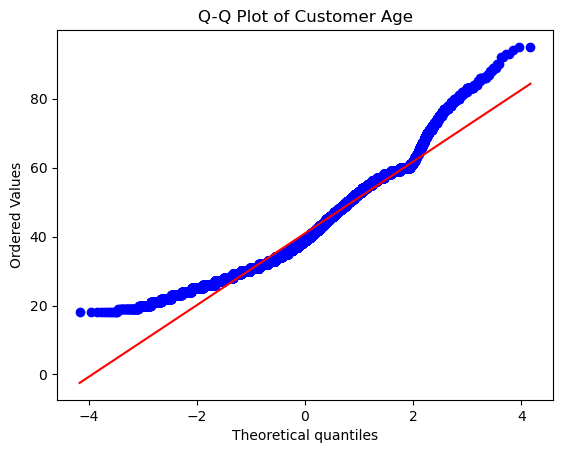

In [24]:
stats.probplot(df_clean["age"], dist="norm", plot=plt)

plt.title("Q-Q Plot of Customer Age")
plt.show()

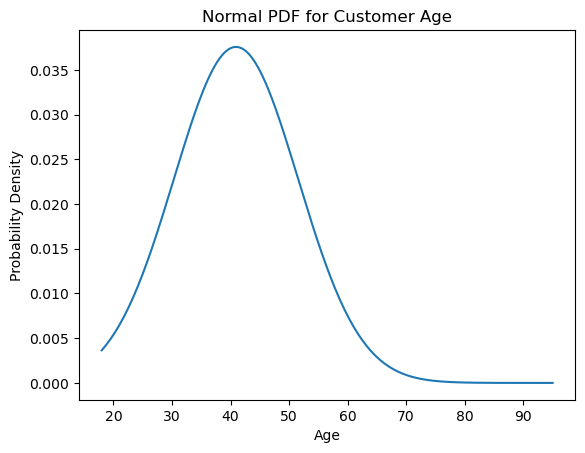

In [25]:
x = np.linspace(age.min(), age.max(), 200)
pdf = norm.pdf(x, mean_age, std_age)

plt.plot(x, pdf)
plt.xlabel("Age")
plt.ylabel("Probability Density")
plt.title("Normal PDF for Customer Age")
plt.show()

## 7. Comparison and Conclusion

I used three probability distributions in this analysis.

The Binomial distribution was used for yes or no subscription results. The Poisson distribution was used for the number of contacts, and the Normal distribution was used for customer age.

The Poisson distribution did not fit the actual data very well because the variance was higher than the mean. The age data was also not perfectly normally distributed.

Overall, this analysis helped me understand how different probability distributions can be used with bank marketing data.